# Predicting Credit Card Default with Logistic Regression and Random Forest
Fundamentals of Machine Learning - Programming Assignment (supervised learning)

**Dataset:** Default of Credit Card Clients, UCI Machine Learning Repository
(https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).
30,000 Taiwanese card holders, April-September 2005, 23 predictors and a binary target.

**Goal:** predict whether a client will miss the next month's payment, and compare two distinct
algorithms (a linear model and a tree ensemble) using several metrics rather than accuracy alone.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             precision_recall_curve, classification_report)

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Loading the data

In [2]:
df = pd.read_csv("data/credit_default.csv")
df = df.rename(columns={"default payment next month": "DEFAULT", "PAY_0": "PAY_1"})
print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df.info()
print("Missing values:", df.isna().sum().sum(), "| duplicated IDs:", df["ID"].duplicated().sum())
df.describe().T.round(1)

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_1      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   30000 non-nu

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.5,8660.4,1.0,7500.8,15000.5,22500.2,30000.0
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_1,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0


## 2. Exploratory analysis

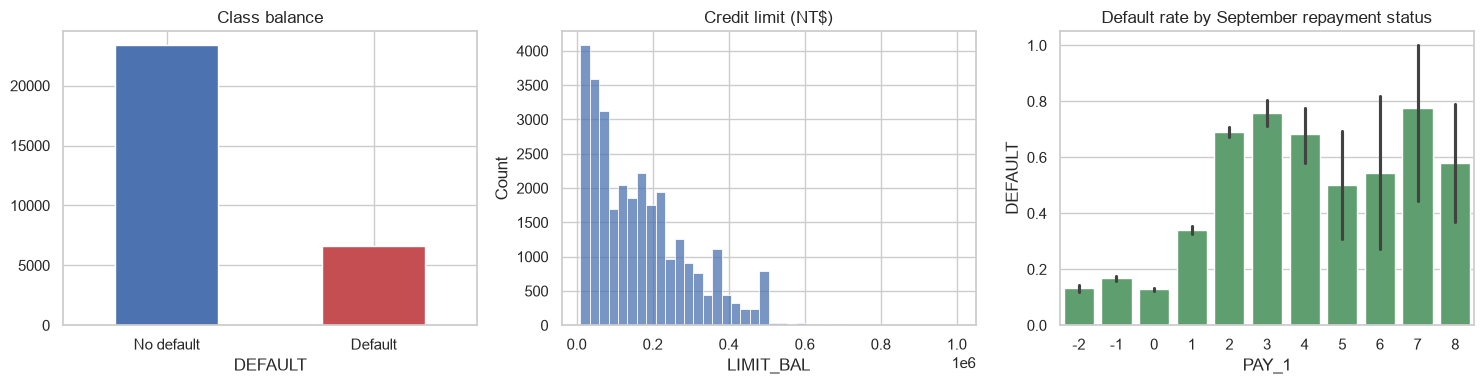

DEFAULT
0    0.779
1    0.221
Name: proportion, dtype: float64


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["DEFAULT"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class balance"); ax[0].set_xticklabels(["No default", "Default"], rotation=0)
sns.histplot(df["LIMIT_BAL"], bins=40, ax=ax[1]); ax[1].set_title("Credit limit (NT$)")
sns.barplot(x="PAY_1", y="DEFAULT", data=df, ax=ax[2], color="#55A868")
ax[2].set_title("Default rate by September repayment status")
plt.tight_layout(); plt.savefig("figures/eda_overview.png", dpi=150); plt.show()
print(df["DEFAULT"].value_counts(normalize=True).round(3))

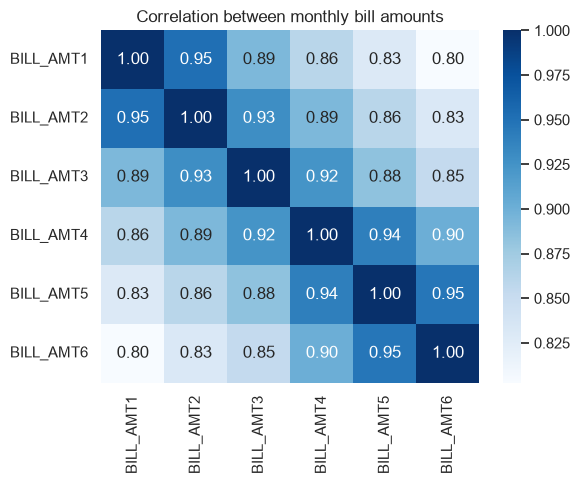

In [5]:
bill = [f"BILL_AMT{i}" for i in range(1, 7)]
plt.figure(figsize=(6, 5))
sns.heatmap(df[bill].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation between monthly bill amounts")
plt.tight_layout(); plt.savefig("figures/bill_corr.png", dpi=150); plt.show()

## 3. Pre-processing

1. `EDUCATION` should only take 1-4. The codes 0, 5 and 6 are undocumented, so they are merged into "others" (4).
2. `MARRIAGE` should only take 1-3. Code 0 is merged into "others" (3).
3. `ID` carries no information and is dropped.
4. Two engineered features summarise the six-month history: average bill and average utilisation of the limit.
5. `SEX`, `EDUCATION`, `MARRIAGE` are nominal, so they are one-hot encoded. The `PAY_x` columns are ordinal
   (months of delay), so they stay numeric.
6. Numeric columns are standardised (needed by logistic regression and PCA; harmless for the forest).
7. The split is 80/20, stratified, and the scaler/encoder are fitted inside a pipeline on the training data only,
   which prevents leakage.

In [6]:
data = df.drop(columns="ID").copy()
data["EDUCATION"] = data["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
data["MARRIAGE"] = data["MARRIAGE"].replace({0: 3})

bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
data["AVG_BILL"] = data[bill_cols].mean(axis=1)
data["AVG_UTILISATION"] = data["AVG_BILL"] / data["LIMIT_BAL"]
data["PAY_RATIO"] = data[pay_amt_cols].sum(axis=1) / (data[bill_cols].clip(lower=0).sum(axis=1) + 1)

X = data.drop(columns="DEFAULT")
y = data["DEFAULT"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

categorical = ["SEX", "EDUCATION", "MARRIAGE"]
numeric = [c for c in X.columns if c not in categorical]
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
    ("num", StandardScaler(), numeric),
])

(24000, 26) (6000, 26) 0.221 0.221


### 3.1 Dimensionality check with PCA
The six bill columns are strongly correlated, so I checked how many principal components are needed.
PCA is used here for analysis; the final models use the original (interpretable) features.

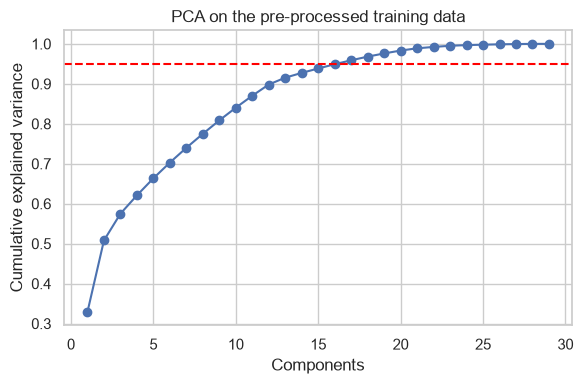

29 features after encoding; 17 components explain 95% of the variance


In [7]:
Xt = preprocess.fit_transform(X_train)
pca = PCA().fit(Xt)
cum = np.cumsum(pca.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95)) + 1
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, color="red", ls="--"); plt.xlabel("Components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA on the pre-processed training data")
plt.tight_layout(); plt.savefig("figures/pca.png", dpi=150); plt.show()
print(f"{Xt.shape[1]} features after encoding; {n95} components explain 95% of the variance")

## 4. Models
Both models are wrapped in a pipeline, tuned with 5-fold stratified cross-validation on the training set only,
and scored on ROC-AUC (threshold independent, robust to imbalance). `class_weight="balanced"` makes errors on
the minority class cost more.

* **Logistic regression** - linear, interpretable baseline.
* **Random forest** - bagged decision trees; captures non-linear effects and interactions.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

log_pipe = Pipeline([("prep", preprocess),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))])
log_grid = {"clf__C": [0.01, 0.1, 1, 10], "clf__penalty": ["l1", "l2"], "clf__solver": ["liblinear"]}

rf_pipe = Pipeline([("prep", preprocess),
                    ("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1))])
rf_grid = {"clf__n_estimators": [200, 400], "clf__max_depth": [6, 10, 16],
           "clf__min_samples_leaf": [5, 20]}

searches = {}
for name, pipe, grid in [("Logistic Regression", log_pipe, log_grid), ("Random Forest", rf_pipe, rf_grid)]:
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name}: best CV ROC-AUC = {gs.best_score_:.4f}\n  params = {gs.best_params_}")

Logistic Regression: best CV ROC-AUC = 0.7272
  params = {'clf__C': 1, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
Random Forest: best CV ROC-AUC = 0.7859
  params = {'clf__max_depth': 16, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 400}


## 5. Results on the held-out test set

In [9]:
rows, probs = [], {}
for name, gs in searches.items():
    p = gs.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, p)})
baseline = (y_test == 0).mean()
results = pd.DataFrame(rows).set_index("Model").round(4)
print(f"Majority-class baseline accuracy: {baseline:.4f}")
results

Majority-class baseline accuracy: 0.7788


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.6815,0.3696,0.6240,0.4643,0.7114
Random Forest,0.7772,0.4968,0.5863,0.5378,0.7775


In [10]:
for name, p in probs.items():
    print("=" * 60, "\n", name)
    print(classification_report(y_test, (p >= 0.5).astype(int), target_names=["No default", "Default"], digits=3))

 Logistic Regression
              precision    recall  f1-score   support

  No default      0.867     0.698     0.773      4673
     Default      0.370     0.624     0.464      1327

    accuracy                          0.681      6000
   macro avg      0.618     0.661     0.619      6000
weighted avg      0.757     0.681     0.705      6000

 Random Forest
              precision    recall  f1-score   support

  No default      0.876     0.831     0.853      4673
     Default      0.497     0.586     0.538      1327

    accuracy                          0.777      6000
   macro avg      0.686     0.709     0.696      6000
weighted avg      0.792     0.777     0.783      6000



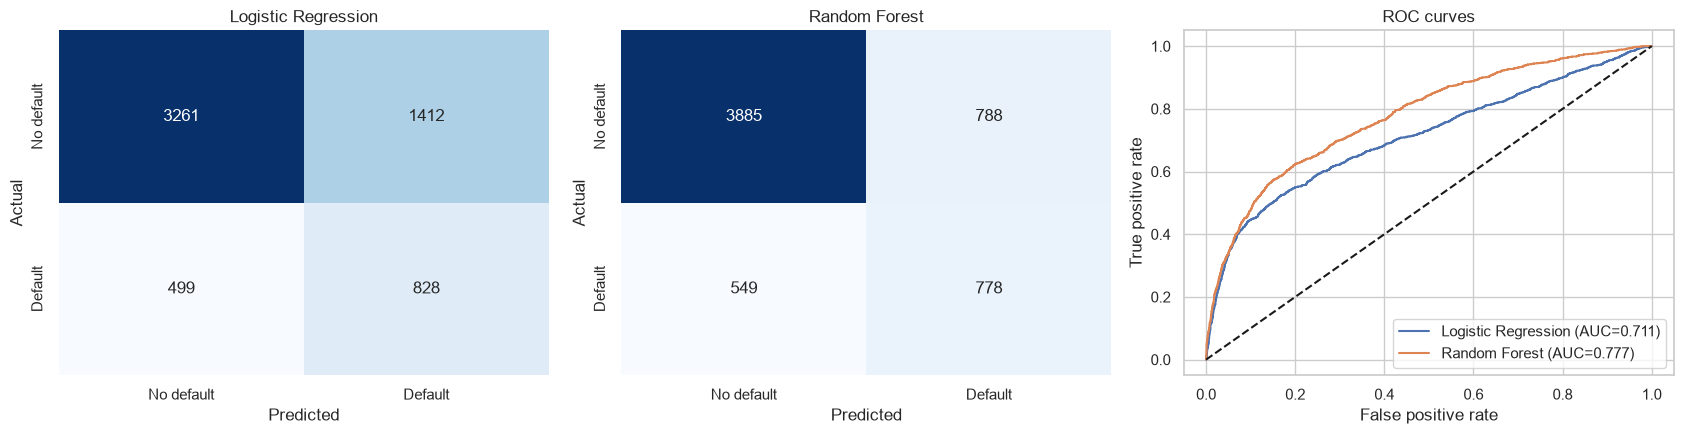

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (name, p) in zip(ax[:2], probs.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["No default", "Default"], yticklabels=["No default", "Default"])
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
ax[2].plot([0, 1], [0, 1], "k--"); ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC curves"); ax[2].legend()
plt.tight_layout(); plt.savefig("figures/confusion_roc.png", dpi=150); plt.show()